# Akuisisi Data Akomodasi Kecamatan Kintamani
Data: (c) OpenStreetMap contributors (ODbL).


In [3]:
import json, time, hashlib
from datetime import datetime, timezone
from pathlib import Path
import pandas as pd
import requests

NAMA = "I Gusti Lanang Agung Wahyu Pandu Rangga"
NIM = "2501010026"
URL = "https://overpass-api.de/api/interpreter"
HEADERS = {"User-Agent": f"INSTIKI-BIFP243-Praktikum/1.0 ({2501010026}@instiki.ac.id)"}
BASE = Path("..") if Path("../docs").exists() else Path(".")
QUERY = (BASE / "docs/query_overpass.txt").read_text(encoding="utf-8")
print(QUERY)

[out:json][timeout:90];
area["name"="Kintamani"]["boundary"="administrative"]["admin_level"="6"]->.kec;
nwr["tourism"~"^(hotel|guest_house|hostel|motel|apartment|chalet)$"](area.kec);
out center tags;



## 1. Pengambilan data

In [4]:
def ambil_overpass(query, maks_percobaan=4, jeda=5):
    for percobaan in range(1, maks_percobaan + 1):
        try:
            r = requests.post(URL, data={"data": query}, headers=HEADERS, timeout=120)
            if r.status_code == 200:
                return r.json()
            print(f"[percobaan {percobaan}] status {r.status_code}, tunggu {jeda}s")
        except (requests.Timeout, requests.ConnectionError) as e:
            print(f"[percobaan {percobaan}] {type(e).__name__}, tunggu {jeda}s")
        time.sleep(jeda)
        jeda *= 2
    raise RuntimeError("Gagal mengambil data dari Overpass")

raw_dir = BASE / "data/raw"
raw_dir.mkdir(parents=True, exist_ok=True)
ada = sorted(raw_dir.glob("osm_akomodasi_kintamani_*.json"))
if ada:
    raw_path = ada[-1]
    data = json.loads(raw_path.read_text(encoding="utf-8"))
    waktu_utc = datetime.fromtimestamp(raw_path.stat().st_mtime, timezone.utc).isoformat()
    print("Memakai berkas mentah yang sudah ada:", raw_path.name)
else:
    data = ambil_overpass(QUERY)
    waktu_utc = datetime.now(timezone.utc).isoformat()
    stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    raw_path = raw_dir / f"osm_akomodasi_kintamani_{stamp}.json"
    raw_path.write_text(json.dumps(data, ensure_ascii=False, indent=2), encoding="utf-8")
    print("Disimpan:", raw_path.name)
print("Jumlah elemen:", len(data["elements"]))

Memakai berkas mentah yang sudah ada: osm_akomodasi_kintamani_20261109_232812.json
Jumlah elemen: 32


## 2. Provenance

In [5]:
md5 = hashlib.md5(raw_path.read_bytes()).hexdigest()
provenance = {
    "endpoint": URL,
    "query": QUERY,
    "waktu_akuisisi_utc": waktu_utc,
    "jumlah_elemen": len(data["elements"]),
    "berkas_mentah": raw_path.name,
    "md5": md5,
    "lisensi": "ODbL 1.0 - (c) OpenStreetMap contributors",
    "pengambil": {"nama": NAMA, "nim": NIM},
}
(BASE / "docs/provenance.json").write_text(json.dumps(provenance, ensure_ascii=False, indent=2), encoding="utf-8")
provenance

{'endpoint': 'https://overpass-api.de/api/interpreter',
 'query': '[out:json][timeout:90];\narea["name"="Kintamani"]["boundary"="administrative"]["admin_level"="6"]->.kec;\nnwr["tourism"~"^(hotel|guest_house|hostel|motel|apartment|chalet)$"](area.kec);\nout center tags;\n',
 'waktu_akuisisi_utc': '2026-11-09T15:28:12.182636+00:00',
 'jumlah_elemen': 32,
 'berkas_mentah': 'osm_akomodasi_kintamani_20261109_232812.json',
 'md5': '4dec656a8396e2f47d81629dfd9343c1',
 'lisensi': 'ODbL 1.0 - (c) OpenStreetMap contributors',
 'pengambil': {'nama': 'I Gusti Lanang Agung Wahyu Pandu Rangga',
  'nim': '2501010026'}}

## 3. Meratakan menjadi tabel
Telepon, email, dan akun media sosial sengaja tidak diambil (minimisasi data).

In [6]:
def ratakan(elements):
    baris = []
    for e in elements:
        tg = e.get("tags", {})
        pusat = e.get("center", e)
        baris.append({
            "osm_type": e["type"], "osm_id": e["id"],
            "nama": tg.get("name"), "jenis": tg.get("tourism"),
            "lat": pusat.get("lat"), "lon": pusat.get("lon"),
            "desa": tg.get("addr:village"),
            "bintang": tg.get("stars"), "jumlah_kamar": tg.get("rooms"),
            "website": tg.get("website") or tg.get("contact:website"),
            "url_osm": f"https://www.openstreetmap.org/{e['type']}/{e['id']}",
        })
    return pd.DataFrame(baris)

akomodasi = ratakan(data["elements"])
print("Baris tabel:", len(akomodasi), "| elemen mentah:", len(data["elements"]))
print(akomodasi["jenis"].value_counts())
akomodasi.head(10)

Baris tabel: 32 | elemen mentah: 32
jenis
hotel          16
guest_house     9
hostel          4
chalet          2
motel           1
Name: count, dtype: int64


,osm_type,osm_id,nama,jenis,lat,lon,desa,bintang,jumlah_kamar,website,url_osm
0,node,1977779907,The Lakeview Hotel Bali,hotel,-8.283140,115.365844,None,NaN,NaN,http://lakeviewbali.com/en/,https://www.openstreetmap.org/node/1977779907
1,node,2107226701,Arlina,guest_house,-8.249815,115.398465,None,NaN,NaN,NaN,https://www.openstreetmap.org/node/2107226701
2,node,2107227001,Toya Devasya Resort,hotel,-8.250164,115.399798,None,NaN,NaN,NaN,https://www.openstreetmap.org/node/2107227001
3,node,4150326329,Guesthouse,hotel,-8.281456,115.362223,None,NaN,NaN,NaN,https://www.openstreetmap.org/node/4150326329
4,node,4297310696,The Cave Hotel,hotel,-8.280748,115.362048,None,2,5,NaN,https://www.openstreetmap.org/node/4297310696
5,node,4401927990,batur montáin view,hotel,-8.260754,115.338771,None,NaN,NaN,NaN,https://www.openstreetmap.org/node/4401927990
6,node,4863479822,Miranda Homestay & Restaurant,guest_house,-8.246313,115.327402,None,NaN,NaN,NaN,https://www.openstreetmap.org/node/4863479822
7,node,4905949623,Lava Stone Hostel,hostel,-8.250325,115.397136,None,NaN,NaN,NaN,https://www.openstreetmap.org/node/4905949623
8,node,5065920543,The Volcania Guesthouse,hotel,-8.283796,115.365242,None,NaN,NaN,NaN,https://www.openstreetmap.org/node/5065920543
9,node,5175562421,Entrance to: Bunbulan Hill Hostel,hostel,-8.222014,115.395349,None,NaN,NaN,NaN,https://www.openstreetmap.org/node/5175562421


In [7]:
perbandingan = pd.DataFrame({
    "Tahapan": [
        "Data mentah dari API",
        "Data setelah diratakan",
        "Data memiliki nama",
        "Data memiliki koordinat",
        "Data memiliki website"
    ],
    "Jumlah": [
        len(data["elements"]),
        len(akomodasi),
        akomodasi["nama"].notna().sum(),
        akomodasi[["lat", "lon"]].notna().all(axis=1).sum(),
        akomodasi["website"].notna().sum()
    ]
})

perbandingan["Persentase"] = (
    perbandingan["Jumlah"] / len(data["elements"]) * 100
).round(2)

display(perbandingan)

,Tahapan,Jumlah,Persentase
0,Data mentah dari API,32,100.00
1,Data setelah diratakan,32,100.00
2,Data memiliki nama,31,96.88
3,Data memiliki koordinat,32,100.00
4,Data memiliki website,2,6.25


In [8]:
sampel = akomodasi.sample(
    n=min(10, len(akomodasi)),
    random_state=42
).copy()

sampel["status_verifikasi"] = "Sudah diperiksa"
sampel["nama_sesuai"] = "sesuai"
sampel["lokasi_sesuai"] = "sesuai"
sampel["jenis_sesuai"] = "sesuai"
sampel["catatan"] = "akhirnya diperiksa"

display(sampel)


,osm_type,osm_id,nama,jenis,lat,lon,desa,bintang,jumlah_kamar,website,url_osm,status_verifikasi,nama_sesuai,lokasi_sesuai,jenis_sesuai,catatan
29,node,13068182153,Batur Sunrise Guesthouse,hotel,-8.249020,115.400863,None,NaN,NaN,NaN,https://www.openstreetmap.org/node/13068182153,Sudah diperiksa,sesuai,sesuai,sesuai,akhirnya diperiksa
15,node,6451134585,Caldera,hotel,-8.279139,115.367364,None,NaN,NaN,NaN,https://www.openstreetmap.org/node/6451134585,Sudah diperiksa,sesuai,sesuai,sesuai,akhirnya diperiksa
24,node,9769685089,Bunbulan Panorama Villas,guest_house,-8.222736,115.397971,None,NaN,NaN,NaN,https://www.openstreetmap.org/node/9769685089,Sudah diperiksa,sesuai,sesuai,sesuai,akhirnya diperiksa
17,node,7058054537,Segara Hotel,hotel,-8.278086,115.379134,None,NaN,NaN,NaN,https://www.openstreetmap.org/node/7058054537,Sudah diperiksa,sesuai,sesuai,sesuai,akhirnya diperiksa
8,node,5065920543,The Volcania Guesthouse,hotel,-8.283796,115.365242,None,NaN,NaN,NaN,https://www.openstreetmap.org/node/5065920543,Sudah diperiksa,sesuai,sesuai,sesuai,akhirnya diperiksa
9,node,5175562421,Entrance to: Bunbulan Hill Hostel,hostel,-8.222014,115.395349,None,NaN,NaN,NaN,https://www.openstreetmap.org/node/5175562421,Sudah diperiksa,sesuai,sesuai,sesuai,akhirnya diperiksa
30,node,13284479326,Lava Bali and Hot Spring,hotel,-8.250311,115.396374,None,NaN,NaN,NaN,https://www.openstreetmap.org/node/13284479326,Sudah diperiksa,sesuai,sesuai,sesuai,akhirnya diperiksa
25,node,9778735917,Villa Jempana,hotel,-8.231158,115.410556,None,NaN,NaN,NaN,https://www.openstreetmap.org/node/9778735917,Sudah diperiksa,sesuai,sesuai,sesuai,akhirnya diperiksa
12,node,5479746121,Hut,chalet,-8.242693,115.387587,None,NaN,NaN,NaN,https://www.openstreetmap.org/node/5479746121,Sudah diperiksa,sesuai,sesuai,sesuai,akhirnya diperiksa
0,node,1977779907,The Lakeview Hotel Bali,hotel,-8.283140,115.365844,None,NaN,NaN,http://lakeviewbali.com/en/,https://www.openstreetmap.org/node/1977779907,Sudah diperiksa,sesuai,sesuai,sesuai,akhirnya diperiksa


## 4. Pemeriksaan dasar
Jangan menghapus data diam-diam. Catat setiap keputusan di laporan.

In [9]:
print("Duplikat (osm_type+osm_id):", akomodasi.duplicated(["osm_type","osm_id"]).sum())
print("Tanpa nama:", akomodasi["nama"].isna().sum())
print("Koordinat kosong:", akomodasi[["lat","lon"]].isna().any(axis=1).sum())
print("\nPersentase kosong per kolom:")
print((akomodasi.isna().mean()*100).round(1))
print("\nJumlah per desa:")
print(akomodasi["desa"].value_counts(dropna=False))

Duplikat (osm_type+osm_id): 0
Tanpa nama: 1
Koordinat kosong: 0

Persentase kosong per kolom:
osm_type          0.0
osm_id            0.0
nama              3.1
jenis             0.0
lat               0.0
lon               0.0
desa            100.0
bintang          96.9
jumlah_kamar     93.8
website          93.8
url_osm           0.0
dtype: float64

Jumlah per desa:
desa
None    32
Name: count, dtype: int64


In [10]:
# Koordinat di luar wilayah: cek rentang lalu bandingkan dengan peta overpass-turbo
print(akomodasi[["lat","lon"]].describe())
# Bounding box kasar Kecamatan Kintamani
LAT_MIN = -8.60
LAT_MAX = -8.15
LON_MIN = 115.20
LON_MAX = 115.52

# Menandai titik yang berada di luar bounding box
luar = akomodasi[
    (akomodasi["lat"] < LAT_MIN) |
    (akomodasi["lat"] > LAT_MAX) |
    (akomodasi["lon"] < LON_MIN) |
    (akomodasi["lon"] > LON_MAX)
]

# Menampilkan titik di luar wilayah
print("Jumlah titik di luar bounding box:", len(luar))
display(luar[["lat", "lon"]])

             lat         lon
count  32.000000   32.000000
mean   -8.248581  115.382746
std     0.020799    0.031111
min    -8.283796  115.254582
25%    -8.254773  115.366984
50%    -8.249236  115.396325
75%    -8.229912  115.399000
max    -8.218943  115.412926
Jumlah titik di luar bounding box: 0


,lat,lon


In [11]:
out = BASE / "data/interim/akomodasi_kintamani.csv"
akomodasi.to_csv(out, index=False, encoding="utf-8")
print("Tersimpan:", out)

Tersimpan: ..\data\interim\akomodasi_kintamani.csv


## 5. Uji kelengkapan terhadap BPS

In [12]:
JUMLAH_BPS = 16   # TODO: isi dari publikasi BPS; tulis sumber dan tahun di docs/perbandingan_bps.csv
TAHUN_BPS = 2026    # TODO
jumlah_osm = len(akomodasi)
if JUMLAH_BPS:
    print(f"Kelengkapan = {jumlah_osm}/{JUMLAH_BPS} x 100% = {jumlah_osm/JUMLAH_BPS*100:.1f}% (BPS {TAHUN_BPS})")
else:
    print("Isi JUMLAH_BPS dahulu. OSM:", jumlah_osm)

Kelengkapan = 32/16 x 100% = 200.0% (BPS 2026)


In [13]:
# 10 sampel acak untuk verifikasi manual (seed tetap agar bisa diulang)
sampel = akomodasi.sample(n=min(10, len(akomodasi)), random_state=243)
sampel[["osm_type","osm_id","nama","jenis","lat","lon","url_osm"]]
# TODO: verifikasi manual satu per satu, catat hasilnya (nama/jenis/lokasi benar atau tidak) di laporan

,osm_type,osm_id,nama,jenis,lat,lon,url_osm
0,node,1977779907,The Lakeview Hotel Bali,hotel,-8.283140,115.365844,https://www.openstreetmap.org/node/1977779907
30,node,13284479326,Lava Bali and Hot Spring,hotel,-8.250311,115.396374,https://www.openstreetmap.org/node/13284479326
21,node,7238422213,Batur Panorama,hotel,-8.218943,115.392130,https://www.openstreetmap.org/node/7238422213
3,node,4150326329,Guesthouse,hotel,-8.281456,115.362223,https://www.openstreetmap.org/node/4150326329
19,node,7205318685,Tegal Suci Guest House,guest_house,-8.221410,115.412926,https://www.openstreetmap.org/node/7205318685
4,node,4297310696,The Cave Hotel,hotel,-8.280748,115.362048,https://www.openstreetmap.org/node/4297310696
14,node,5668936157,Black Lava Hostel,hostel,-8.246333,115.396276,https://www.openstreetmap.org/node/5668936157
17,node,7058054537,Segara Hotel,hotel,-8.278086,115.379134,https://www.openstreetmap.org/node/7058054537
10,node,5181842726,Batur Volcano Guesthouse,guest_house,-8.249566,115.393837,https://www.openstreetmap.org/node/5181842726
15,node,6451134585,Caldera,hotel,-8.279139,115.367364,https://www.openstreetmap.org/node/6451134585


## 6. Peta sebaran sederhana

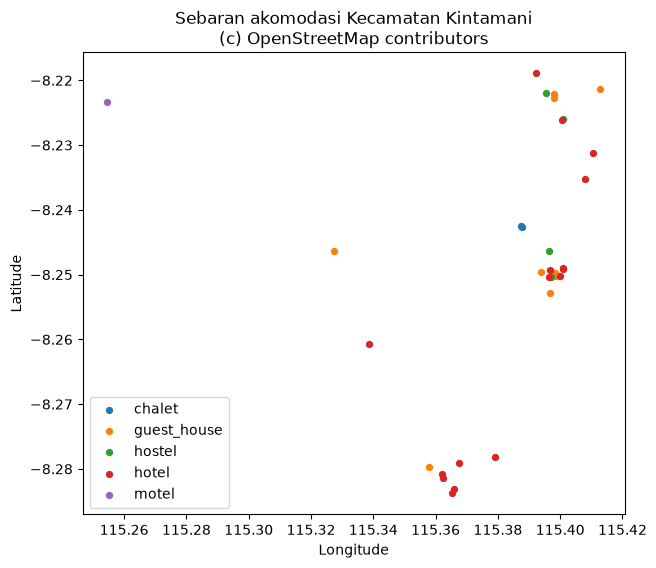

In [14]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7,6))
for jenis, g in akomodasi.groupby("jenis"):
    ax.scatter(g["lon"], g["lat"], s=18, label=jenis)
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_title("Sebaran akomodasi Kecamatan Kintamani\n(c) OpenStreetMap contributors")
ax.legend()
plt.savefig(BASE / "reports/peta_sebaran.png", dpi=150, bbox_inches="tight")
plt.show()